# Threshold curve in the $(p, p_{\mathrm{bell},z})$ plane — Bell models & equivalents

Headline figure: every fitted threshold is a 2D point $(p^*, p_{\mathrm{bell},z}^*)$
on the noise plane. Each noise model is drawn as a separate curve.

- **bias scan**: direction $\beta = p_{\mathrm{bell},z}/p$, threshold lands at
  $(p^*, \beta \cdot p^*)$.
- **fixed-$p_{\mathrm{bell},z}$ scan**: $p_{\mathrm{bell},z}$ held constant,
  threshold lands at $(p^*, p_{\mathrm{bell},z}^{\mathrm{fixed}})$.

`biased_bell_v2` / `biased_bell_v3` fits come pre-computed from
`threshold_comparison_bell.ipynb` (`out/collection/threshold_bell_fits.csv`).
The single-ancilla equivalents — `biased_bell_v3_equivalent` and
`biased_bell_v3_equivalent_majority` — are fitted in-place from their raw decode
CSVs (`out/collection/threshold_equivalent,*.csv` and
`threshold_equivalent_majority,*.csv`, written by `tools/equivalent/run_decode*.sh`).
Each equivalent should land on top of `biased_bell_v3`; the majority variant
trades extra rounds for a lower effective measurement error.

In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Shared analysis backend (also used by tools/plot_thresholds_bell.py) so the
# notebook and the CLI produce identical figures.
from bell_threshold_analysis import (
    load_decode_csvs,
    fit_thresholds,
    plot_threshold_plane,
    plot_threshold_vs_fixed_pbz,
    plot_combined_plane,
)

%load_ext autoreload
%autoreload 2

In [2]:
fits_path = Path('../out/collection/threshold_bell_fits.csv')
if not fits_path.exists():
    raise FileNotFoundError(
        f'No fits at {fits_path}. Run threshold_comparison_bell.ipynb first.'
    )

fits_df = pd.read_csv(fits_path)

# Backwards-compat: older fits CSVs lacked the noise_model column.
if 'noise_model' not in fits_df.columns:
    fits_df['noise_model'] = 'biased_bell_v2'

print('fits per noise_model:')
print(fits_df.groupby('noise_model').size())
fits_df

fits per noise_model:
noise_model
biased_bell_v2    12
biased_bell_v3    11
dtype: int64


,noise_model,direction,direction_kind,bias,p_bell_z_fixed,p_th,p_th_err,mu,mu_err,p_init,n_points
0,biased_bell_v2,bias=0,bias,0.0,NaN,0.002418,2.159251e-05,0.910499,0.044097,0.002512,15
1,biased_bell_v2,bias=1,bias,1.0,NaN,0.002047,1.233021e-05,0.971927,0.035426,0.002154,14
2,biased_bell_v2,bias=2,bias,2.0,NaN,0.001701,2.051408e-05,0.756509,0.026000,0.001585,13
3,biased_bell_v2,bias=3,bias,3.0,NaN,0.001486,9.182376e-06,0.954573,0.026916,0.001585,14
4,biased_bell_v2,bias=5,bias,5.0,NaN,0.001196,1.259919e-05,0.815859,0.025822,0.001166,13
5,biased_bell_v2,bias=10,bias,10.0,NaN,0.000795,4.923095e-06,0.880964,0.021115,0.000858,14
6,biased_bell_v2,bias=20,bias,20.0,NaN,0.000492,6.146875e-06,0.713299,0.025259,0.000464,13
7,biased_bell_v2,bias=30,bias,30.0,NaN,0.000348,2.581181e-06,0.791440,0.017868,0.000341,13
8,biased_bell_v2,bias=50,bias,50.0,NaN,0.000220,1.991365e-06,0.884524,0.030904,0.000251,12
9,biased_bell_v2,bias=100,bias,100.0,NaN,0.000116,8.823396e-07,0.963759,0.036348,0.000136,9


In [ ]:
# Append the equivalent models. Unlike v2/v3 (pre-fitted in
# threshold_comparison_bell.ipynb), the equivalent results are raw decode CSVs
# from tools/equivalent/run_decode*.sh, so we fit them here with the same shared
# locate -> quadratic-FSS pipeline (src/bell_threshold_analysis.py), then concat
# onto fits_df. Each CSV's metadata carries the right noise_model, so the
# single-ancilla equivalent and its majority-vote variant separate automatically.
EQUIV_CSV_GLOBS = [
    '../out/collection/threshold_equivalent,*.csv',
    '../out/collection/threshold_equivalent_majority,*.csv',
]
# Equivalent model names this cell owns (stale rows are dropped before append).
EQUIV_MODELS = [
    'biased_bell_v3_equivalent',
    'biased_bell_v3_equivalent_majority',
]

try:
    edf = load_decode_csvs(EQUIV_CSV_GLOBS)
except FileNotFoundError:
    print(f'No equivalent CSVs matched {EQUIV_CSV_GLOBS}; skipping.')
    equiv_fits_df = pd.DataFrame()
else:
    # LOGICAL_CUTOFF=0.45 here (looser than v2/v3) to keep more points.
    equiv_fits_df = fit_thresholds(edf, n_per_side=2, logical_cutoff=0.45, verbose=True)
    # Drop any stale equivalent rows, then append the freshly-fitted ones.
    fits_df = fits_df[~fits_df['noise_model'].isin(EQUIV_MODELS)]
    fits_df = pd.concat([fits_df, equiv_fits_df], ignore_index=True)

    print(f'\nFitted {len(equiv_fits_df)} equivalent-model directions.')
    print('fits per noise_model (after append):')
    print(fits_df.groupby('noise_model').size())

equiv_fits_df if not equiv_fits_df.empty else fits_df

In [ ]:
# Summary of what will be plotted. The per-model bias / fixed-pbz grouping now
# lives inside the plot functions (bell_threshold_analysis), so all the plotting
# cells below need is `fits_df`.
print('fits per (noise_model, direction_kind):')
print(fits_df.groupby(['noise_model', 'direction_kind']).size())

In [ ]:
# Each fitted threshold -> point (p_th, beta * p_th) on the (p, p_bell_z) plane.
# One curve per noise model. v3, its single-ancilla equivalent, and the
# majority-vote variant should fall on top of each other (equivalence check).
# Same figure tools/plot_thresholds_bell.py writes as threshold_bell_curves.pdf.
fig = plot_threshold_plane(fits_df)
Path('../out/figures').mkdir(parents=True, exist_ok=True)
fig.savefig('../out/figures/threshold_bell_curves.pdf', bbox_inches='tight')
plt.show()

In [ ]:
# p_th vs fixed p_bell_z (independent scan, easier to interpret experimentally
# because p_bell_z is set by hardware). One curve per noise model.
fig = plot_threshold_vs_fixed_pbz(fits_df)
if fig is not None:
    plt.show()
else:
    print('No fixed-pbz fits to plot.')

In [ ]:
# Combined view: both scans on one (p_bell_z, p) plane, one set of curves per
# noise model.
# - bias scan: each point is (p_th * beta, p_th).
# - fixed-pbz scan: each point is (p_bell_z_fixed, p_th).
fig = plot_combined_plane(fits_df)
plt.show()

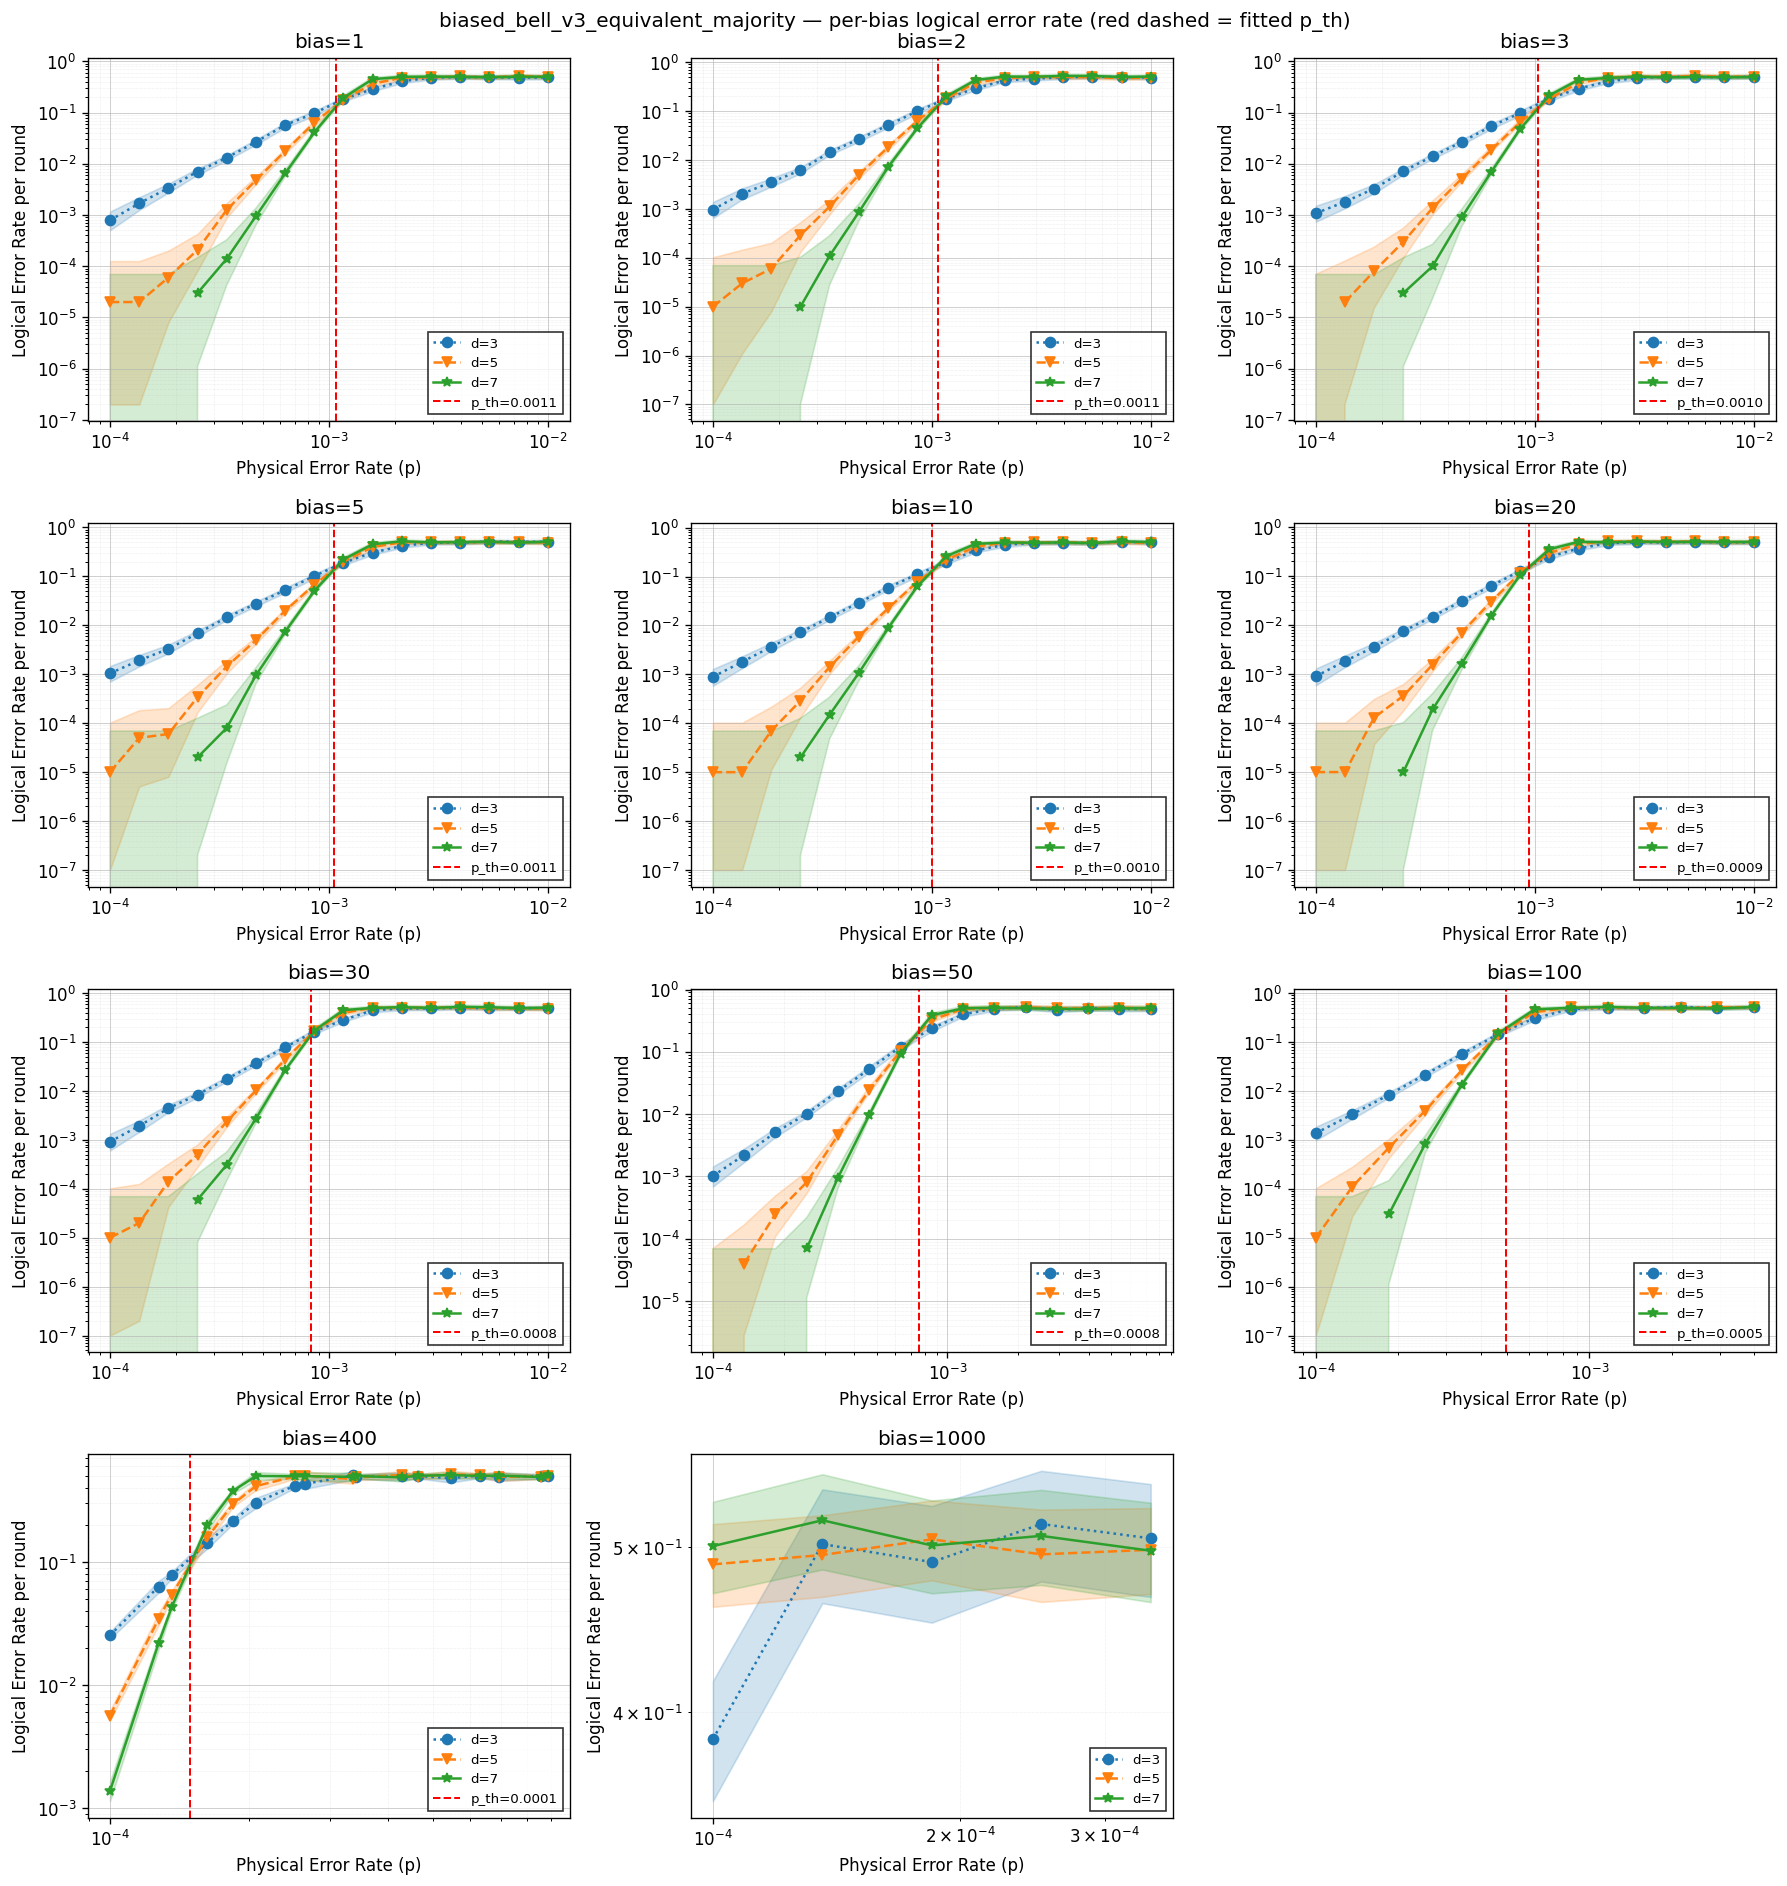

In [8]:
# DEBUG: per-bias logical-error-rate curves for a single noise model, drawn with
# sinter.plot_error_rate so each distance gets its own color (linestyle also
# encodes distance). The fitted threshold is a red vertical dashed line. One
# subplot per bias. Same plotting helper/style as the per-direction cell in
# threshold_comparison.ipynb.
#
# fits_df only holds fitted points, so we reload the raw decode CSV for the
# chosen model here.
import sinter

FIGURES_NOISE_MODEL = 'biased_bell_v3_equivalent_majority'

# Raw decode CSV glob per model family.
RAW_CSV_GLOBS = {
    'biased_bell_v2': '../out/collection/threshold_bell,*.csv',
    'biased_bell_v3': '../out/collection/threshold_bell,*.csv',
    'biased_bell_v3_equivalent': '../out/collection/threshold_equivalent,*.csv',
    'biased_bell_v3_equivalent_majority':
        '../out/collection/threshold_equivalent_majority,*.csv',
}
LINESTYLES = {2: ':', 3: ':', 4: '--', 5: '--', 6: '-', 7: '-'}


def _plot_args_func(index, group_key, group_stats):
    d = group_stats[0].json_metadata['expected_distance']
    return {'linestyle': LINESTYLES.get(d, '-')}


raw_files = sorted(glob.glob(RAW_CSV_GLOBS[FIGURES_NOISE_MODEL]))
if not raw_files:
    print(f'No raw CSVs for {FIGURES_NOISE_MODEL} '
          f'({RAW_CSV_GLOBS[FIGURES_NOISE_MODEL]}); skipping debug plots.')
else:
    fdf = pd.concat([pd.read_csv(f) for f in raw_files], ignore_index=True)
    fdf = fdf.groupby('strong_id').agg({
        'shots': 'sum', 'errors': 'sum', 'discards': 'sum', 'seconds': 'sum',
        'decoder': 'first', 'json_metadata': 'first',
    }).reset_index()
    fmeta = fdf['json_metadata'].apply(
        lambda m: ast.literal_eval(m) if isinstance(m, str) else dict(m)
    )
    fdf['_meta'] = fmeta
    for col in ['direction_kind', 'bias', 'noise_model']:
        fdf[col] = fmeta.apply(lambda m, c=col: m.get(c))

    fdf = fdf[(fdf['noise_model'] == FIGURES_NOISE_MODEL)
              & (fdf['direction_kind'] == 'bias')]
    biases = sorted(fdf['bias'].dropna().unique())

    # p_th per bias from the already-computed fits_df.
    fits_lookup = {
        row['bias']: row['p_th']
        for _, row in fits_df[
            (fits_df['noise_model'] == FIGURES_NOISE_MODEL)
            & (fits_df['direction_kind'] == 'bias')
        ].iterrows()
    }

    if not biases:
        print(f'No bias directions found for {FIGURES_NOISE_MODEL}.')
    else:
        ncols = 3
        nrows = (len(biases) + ncols - 1) // ncols
        fig, axes = plt.subplots(
            nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False
        )

        for idx, bias in enumerate(biases):
            ax = axes[idx // ncols][idx % ncols]
            grp = fdf[fdf['bias'] == bias]

            stats = [
                sinter.TaskStats(
                    strong_id=row['strong_id'],
                    decoder=row['decoder'],
                    json_metadata=row['_meta'],
                    shots=int(row['shots']),
                    errors=int(row['errors']),
                    discards=int(row['discards']),
                    seconds=float(row['seconds']),
                )
                for _, row in grp.iterrows()
            ]

            sinter.plot_error_rate(
                ax=ax,
                stats=stats,
                x_func=lambda stat: stat.json_metadata['p'],
                group_func=lambda stat: f"d={stat.json_metadata['expected_distance']}",
                plot_args_func=_plot_args_func,
                failure_units_per_shot_func=lambda stat: 1,
                failure_values_func=lambda stat: stat.json_metadata['k'],
            )

            p_th = fits_lookup.get(bias)
            if p_th is not None and np.isfinite(p_th):
                ax.axvline(p_th, color='red', linestyle='--', linewidth=1.2,
                           label=f'p_th={p_th:.4f}')

            ax.loglog()
            ax.set_xlabel('Physical Error Rate (p)')
            ax.set_ylabel('Logical Error Rate per round')
            ax.set_title(f'bias={bias:g}')
            ax.grid(which='major', linestyle='-', linewidth=0.5, alpha=0.7)
            ax.grid(which='minor', linestyle=':', linewidth=0.3, alpha=0.5)
            handles, labels = ax.get_legend_handles_labels()
            if handles:
                ax.legend(loc='lower right', frameon=True, edgecolor='black',
                          fancybox=False, fontsize=8)

        for idx in range(len(biases), nrows * ncols):
            fig.delaxes(axes[idx // ncols][idx % ncols])

        fig.suptitle(
            f'{FIGURES_NOISE_MODEL} — per-bias logical error rate '
            f'(red dashed = fitted p_th)'
        )
        fig.tight_layout()
        fig.set_dpi(120)
        plt.show()

Saved ../out/figures/20260629_honeycomb_threshold_equivalent_log.pdf


/var/folders/8g/7b0sw56542b6xspbj28nxd0h0000gq/T/ipykernel_16803/1082333041.py:64: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(


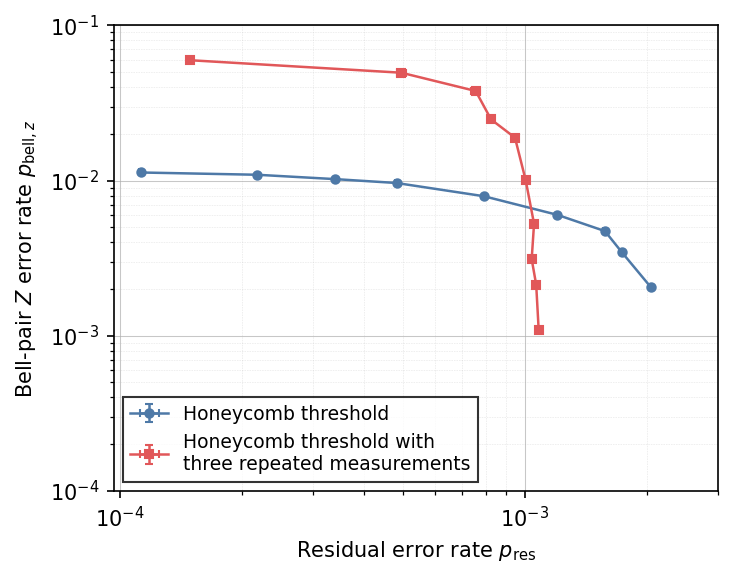

Saved ../out/figures/20260629_honeycomb_threshold_equivalent_linear.pdf


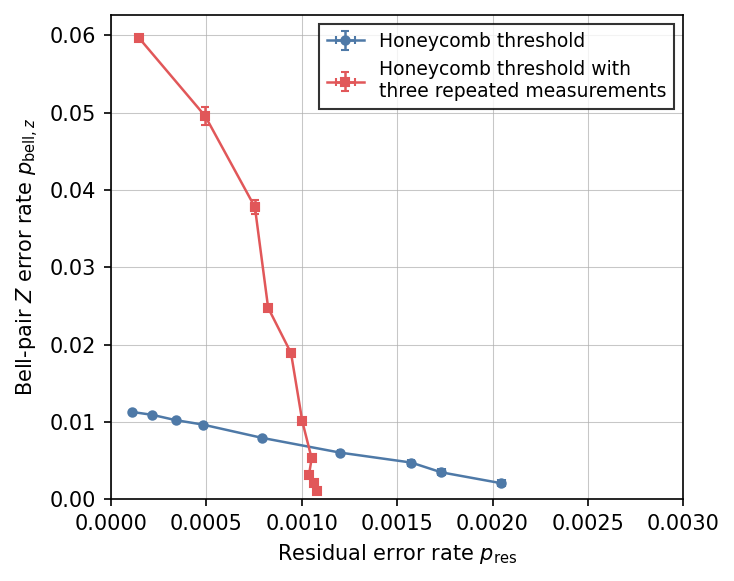

In [99]:
# Paper-ready figure: threshold curve on the (p_res, p_bell_z) plane for the
# two equivalent honeycomb models. Each fitted threshold (bias scan) is a point
# (p_th, bias * p_th). Style follows notebooks/high_rate.ipynb. Two versions are
# produced: log-log and linear. Both use the SAME limits on the x and y axes.
import datetime

plt.rcParams.update({
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
})

# (model, label, color, marker) in plot order.
PAPER_MODELS = [
    ('biased_bell_v3_equivalent', 'Honeycomb threshold', '#4e79a7', 'o'),
    ('biased_bell_v3_equivalent_majority',
     'Honeycomb threshold with \nthree repeated measurements', '#e15759', 's'),
]


def _model_points(model):
    """Return (p, p_err, pbz, pbz_err) arrays for a model's bias scan."""
    bdf = bias_by_model.get(model)
    if bdf is None or bdf.empty:
        return None
    bdf = bdf.sort_values('bias')
    p = bdf['p_th'].to_numpy(dtype=float)
    p_err = bdf['p_th_err'].to_numpy(dtype=float)
    bias = bdf['bias'].to_numpy(dtype=float)
    return p, p_err, bias * p, bias * p_err


# Shared axis limits: same range on x and y, covering both models' points.
_all = [pts for m, *_ in PAPER_MODELS if (pts := _model_points(m)) is not None]
_vals = np.concatenate([np.concatenate([pts[0], pts[2]]) for pts in _all])
_vals = _vals[np.isfinite(_vals) & (_vals > 0)]
LIM_LOG = (10 ** np.floor(np.log10(_vals.min())), 10 ** np.ceil(np.log10(_vals.max())))
LIM_LINEAR = (0.0, _vals.max() * 1.05)


def _make_figure(scale):
    fig, ax = plt.subplots(figsize=(5, 4))
    for model, label, color, marker in PAPER_MODELS:
        pts = _model_points(model)
        if pts is None:
            continue
        p, p_err, pbz, pbz_err = pts
        ax.errorbar(
            p, pbz, xerr=p_err, yerr=pbz_err,
            marker=marker, markersize=4, linewidth=1.2, capsize=2,
            color=color, label=label,
        )

    if scale == 'log':
        ax.set_xscale('log')
        ax.set_yscale('log')
        lim = LIM_LOG
    else:
        lim = LIM_LINEAR
    # Same limits on both axes.
    ax.set_xlim(
        [0,0.003]
    )
    ax.set_ylim(lim)
    # ax.set_aspect('equal', adjustable='box')

    ax.set_xlabel(r'Residual error rate $p_{\text{res}}$')
    ax.set_ylabel(r'Bell-pair $Z$ error rate $p_{\mathrm{bell},z}$')
    ax.grid(which='major', linestyle='-', linewidth=0.5, alpha=0.7)
    ax.grid(which='minor', linestyle=':', linewidth=0.3, alpha=0.5)
    ax.legend(frameon=True, edgecolor='black', fancybox=False) # loc='upper left',

    fig.tight_layout()
    fig.set_dpi(150)
    return fig


out_dir = Path('../out/figures')
out_dir.mkdir(parents=True, exist_ok=True)
date = datetime.date.today().strftime('%Y%m%d')

for scale in ('log', 'linear'):
    fig = _make_figure(scale)
    out_path = out_dir / f'{date}_honeycomb_threshold_equivalent_{scale}.pdf'
    fig.savefig(out_path, bbox_inches='tight')
    print(f'Saved {out_path}')
    plt.show()